In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import corner

from v2_fm_pmssm.data import load_data, pMSSM_Dataset, select, all_var, inverse_transform
from v2_fm_pmssm.training import load_run, generate

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [12]:
run = "fm_32393435"
n_samples = 100_000         # number of test points used in the plots
step_size = 0.05            # step size for ode solver
final = True
input_dir = "checkpoints/"
sample_mode = "load"         # "run": sample here | "save": write inputs for sample_fm.py and stop | "load": read its outputs
omega_0 = 0.12              # fixed relic density for p(inputs | Omega = omega_0)
max_test_files = None       # None = all 50 test files; a small number for quick tests

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

def save_fig(fig, name):  # CHANGED: save instead of plt.show()
    fig.savefig(f"{input_dir}{run}/{name}.png", dpi=120)
    plt.close(fig)
    print(f"saved {input_dir}{run}/{name}.png", flush=True)

Using: cpu


In [4]:
# ---- checkpoint and test set (the fixed test files saved in the checkpoint) ----
checkpoint = torch.load(f"{input_dir}{run}/{run}_weights.pt", map_location=device, weights_only=False)
hparams = checkpoint["hparams"]
mean, std = checkpoint["mean"].to(device), checkpoint["std"].to(device)

test_files = [os.path.join(hparams["data_folder"], f) for f in checkpoint["test_files"]]
parameter, parameter_table, point_id, _ = load_data(exact_paths=test_files, max_files=max_test_files,
                                                    param_names=checkpoint["variables"])
var_registry = select(all_var, branches=checkpoint["variables"])  # the variables the model was trained on
test = pMSSM_Dataset(parameter_table, point_id, var_registry, device).filter_invalid(branches=['MO_Omega'])
test.transform(mean, std)    # mean and std of the training set, from the checkpoint
print(f"test points: {len(test)}")

vf = load_run(run, input_dir, device, final)["model"]   # rebuilt as trained, weights loaded, eval mode

names = [v.branch for v in var_registry]
n_var = len(names)
i_omega = names.index('MO_Omega')
i_inputs = [j for j, v in enumerate(var_registry) if v.data_type == "theory_parameter"]
i_observables = [j for j in range(n_var) if j not in i_inputs]
is_input = torch.tensor([v.data_type == "theory_parameter" for v in var_registry])
masks = {"inputs_known":  is_input,                                         # inputs known -> generate the observables
         "omega_known":   torch.tensor([n == "MO_Omega" for n in names]),   # Omega known -> generate the rest
         "nothing_known": torch.zeros(n_var, dtype=torch.bool)}            # unconditional

---Load pMSSM dataset v2---
Loading files: 50/50
Loaded 50 files from given paths
Total samples: 400000
test points: 318201


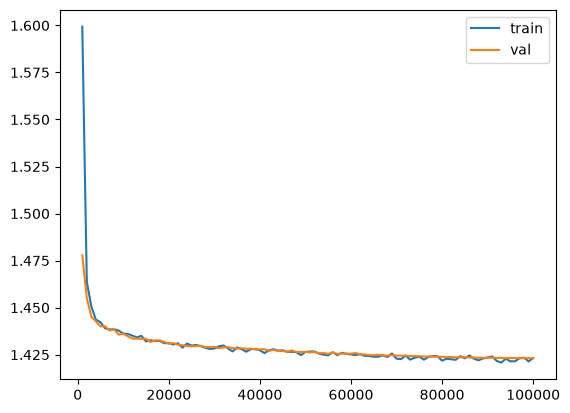

In [5]:
loss_history = np.load(f"{input_dir}{run}/{run}_loss_history.npz")
plt.plot(loss_history['step'], loss_history["train_loss"], label='train')
plt.plot(loss_history['step'], loss_history["val_loss"], label='val')
plt.legend(loc="upper right")
plt.show()

In [6]:
# ---- notebook: sampling setup ------------------------------------------------
n_samples = min(n_samples, len(test))

In [7]:
def gen(known, x_known=None, n=n_samples):
    '''Samples with the known columns fixed to x_known: all columns (n, n_var), normalized.
    known: (n_var,) bool; x_known: (n, n_var) or (1, n_var) normalized. See training/evaluation.py.'''
    return generate(vf, known, x_known, n=n, step_size=step_size, wanted=list(range(n_var)))

def to_physical(x_norm):
    '''normalized (n, n_var) -> numpy array in physical units; works on a copy, x_norm stays normalized'''
    return inverse_transform(x_norm.to(device).clone(), var_registry, mean, std).cpu().numpy()

In [8]:
# Test points used as conditions (random subset, the split indices are sorted by file)
sel = torch.randperm(len(test), generator=torch.Generator().manual_seed(0))[:n_samples].to(test.parameters.device)
test_x = test.parameters[sel]          # normalized
truth_all = to_physical(test.parameters)  # whole test set in physical units
truth = truth_all[sel.cpu().numpy()]      # the selected points in physical units

def _plot_values(x, j):
    '''Column j for plotting; MO_Omega is shown as log10 since it spans orders of magnitude.'''
    return (np.log10(x[:, j]), 'log10(MO_Omega)') if j == i_omega else (x[:, j], names[j])

def plot_marginals(samples, fig_name=None, cols=None, ncols=4, bins=50):  # CHANGED: name of the saved figure
    '''samples: {label: (n, n_var) physical array}. Grid of 1D histograms as in dataset_inspection.ipynb;
    the binning range comes from the first entry (0.5-99.5 percentile).'''
    cols = list(range(len(names))) if cols is None else list(cols)
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False, constrained_layout=True)
    for ax, j in zip(axes.flat, cols):
        ref, title = _plot_values(next(iter(samples.values())), j)
        rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
        for label, x in samples.items():
            v, _ = _plot_values(x, j)
            ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
        ax.set_title(title, fontsize=9)
        ax.set_ylabel('Density')
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)

def plot_corner(samples, fig_name=None, cols=None):  # CHANGED: name of the saved figure
    '''Overlaid corner plots, one color per entry of samples.'''
    cols = list(range(len(names))) if cols is None else list(cols)
    prep = {k: np.column_stack([_plot_values(x, j)[0] for j in cols]) for k, x in samples.items()}
    labels = [_plot_values(next(iter(samples.values())), j)[1] for j in cols]
    ref = next(iter(prep.values()))
    rng = [tuple(np.nanpercentile(ref[:, i], [0.5, 99.5])) for i in range(len(cols))]
    fig = None
    for c, (label, x) in enumerate(prep.items()):
        x = x[np.isfinite(x).all(axis=1)]
        fig = corner.corner(x, fig=fig, color=f'C{c}', labels=labels, range=rng, bins=30,
                            hist_kwargs={'density': True}, plot_datapoints=False, plot_density=False,
                            levels=(0.68, 0.95), label_kwargs={'fontsize': 8})
    handles = [plt.Line2D([], [], color=f'C{c}', label=label) for c, label in enumerate(prep)]
    fig.legend(handles=handles, loc='upper right', fontsize=14)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)


def plot_gen_vs_truth(samples, var_names, fig_name=None, cols=None, ncols=4, bins=50):
    """samples: {truth_label:truth (N, D), gen_label:generated data (N, D)}"""
    cols = list(range(len(names))) if cols is None else list(cols)
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False, constrained_layout=True)
    for ax, j in zip(axes.flat, cols):
        values = list(samples.values())
        true_var = values[0][:, j]
        gen_var = values[1][:, j]
        ax.scatter(true_var, gen_var, s=1, alpha=0.5)
        lims = [min(true_var.min(), gen_var.min()), max(true_var.max(), gen_var.max())]
        ax.plot(lims, lims, 'r--', lw=1)
        ax.set_title(var_names[j], fontsize=9)
        labels = list(samples.keys())
        ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1])
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.show()
    if not fig_name is None: save_fig(fig, fig_name)

In [13]:
# ---- sampling: here ("run"), or hand off to sample_fm.py ("save" -> sbatch -> "load") ----
x_fixed = torch.zeros(n_samples, n_var, device=device)
x_fixed[:, i_omega] = (np.log10(omega_0) - test.mean[i_omega].item()) / test.std[i_omega].item()  # same transform as the data

jobs = {   # name -> keyword arguments of generate()
    'joint':                    dict(known=masks["nothing_known"]),                  # unconditional
    'omega_given_inputs':       dict(known=masks["inputs_known"], x_known=test_x),   # inputs known
    'inputs_given_omega':       dict(known=masks["omega_known"], x_known=test_x),    # Omega known
    'inputs_given_omega_fixed': dict(known=masks["omega_known"], x_known=x_fixed),   # Omega = omega_0
}
settings = dict(run=run, final=final, step_size=step_size, n_samples=n_samples, omega_0=omega_0)
inputs_path = f"{input_dir}{run}/sampling_inputs.pt"
outputs_path = f"{input_dir}{run}/sampling_outputs.pt"

if sample_mode == "run":
    results = {name: gen(**job) for name, job in jobs.items()}

elif sample_mode == "save":
    jobs_cpu = {name: {k: v.cpu() for k, v in job.items()} | {'n': n_samples} for name, job in jobs.items()}
    torch.save({'settings': settings, 'jobs': jobs_cpu}, inputs_path)
    print(f"saved {inputs_path}")
    raise SystemExit(f"Now sample on a GPU:  sbatch tests/slurm/sample_fm.sbatch {run}\n"
                     f"then set sample_mode = 'load' and run the notebook again.")

elif sample_mode == "load":
    outputs = torch.load(outputs_path, map_location=device)
    if outputs['settings'] != settings:
        raise ValueError(f"{outputs_path} was sampled with {outputs['settings']}, "
                         f"but the notebook uses {settings}. Run 'save' and sample_fm.py again.")
    missing = set(jobs) - set(outputs['results'])
    if missing:
        raise ValueError(f"{outputs_path} has no results for {sorted(missing)}. Resubmit sample_fm.sbatch.")
    results = {name: x.to(device) for name, x in outputs['results'].items()}

else:
    raise ValueError(f"sample_mode must be 'run', 'save' or 'load', not {sample_mode!r}")

/tmp/ipykernel_19929/1480088054.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:19: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1791585344983/work/aten/src/ATen/native/IndexingUtils.h:37.)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
/tmp/ipykernel_19929/1480088054.py:22: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered 

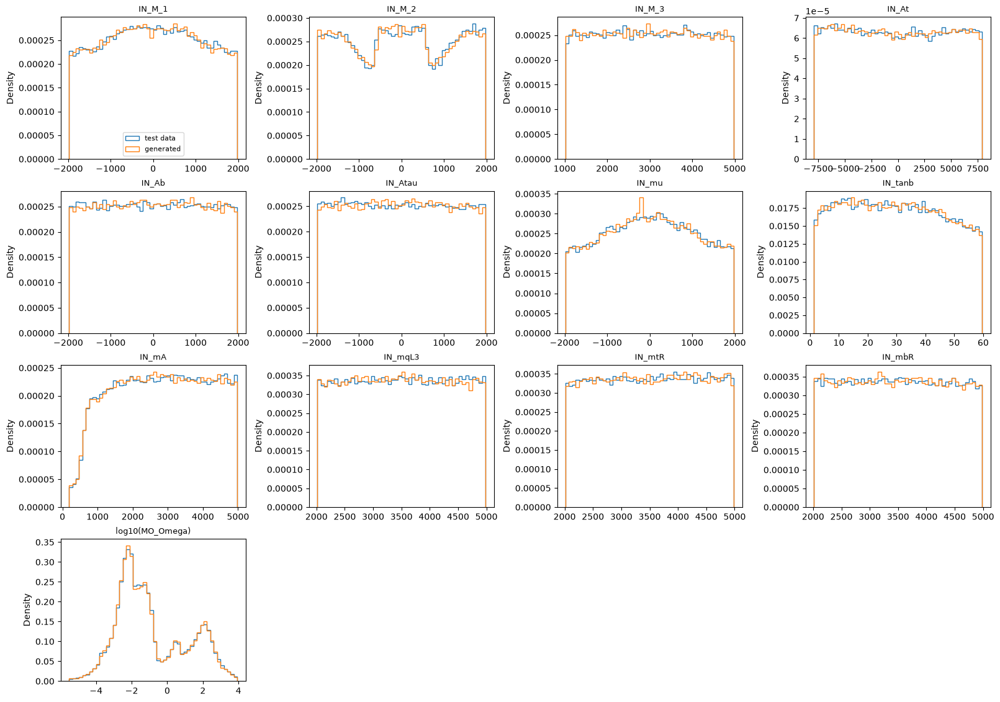

In [14]:
# ---- 1. Joint distribution p(inputs, Omega) ---------------------------------
gen_joint = to_physical(results['joint'])
plot_marginals({'test data': truth, 'generated': gen_joint})

/tmp/ipykernel_19929/1480088054.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return (np.log10(x[:, j]), 'log10(MO_Omega)') if j == i_omega else (x[:, j], names[j])


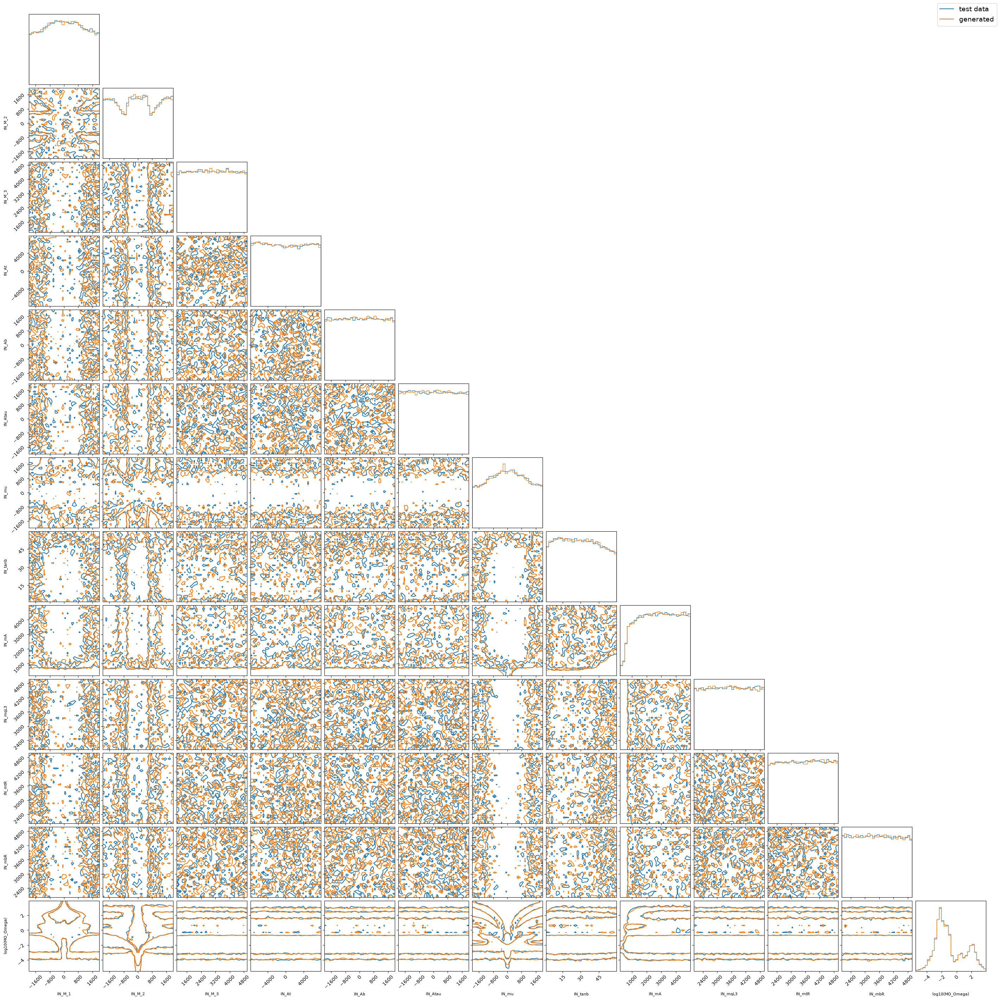

In [15]:
plot_corner({'test data': truth, 'generated': gen_joint})

/tmp/ipykernel_19929/1803039145.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  m1 = np.abs(truth[:, names.index('IN_M_1')])
/tmp/ipykernel_19929/1803039145.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax.hist(np.log10(g_om / t_om), bins=60)


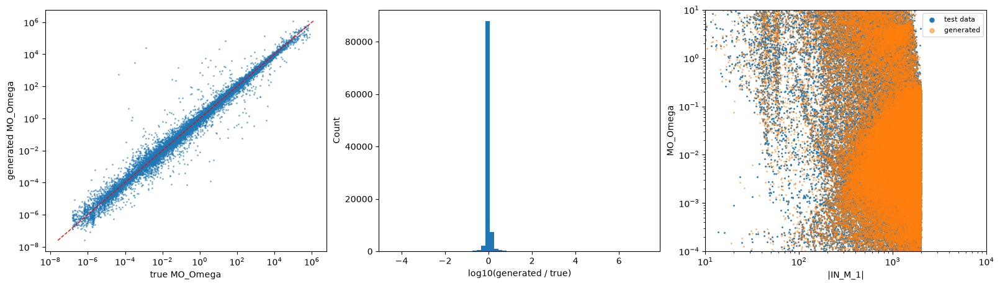

median |log10(generated/true)| = 0.009


/tmp/ipykernel_19929/1803039145.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f"median |log10(generated/true)| = {np.median(np.abs(np.log10(g_om / t_om))):.3f}")


In [16]:
# ---- 2. Relic density from the inputs p(Omega | inputs) ---------------------
gen_omega = to_physical(results['omega_given_inputs'])
t_om, g_om = truth[:, i_omega], gen_omega[:, i_omega]
m1 = np.abs(truth[:, names.index('IN_M_1')])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

ax = axes[0]
ax.scatter(t_om, g_om, s=1, alpha=0.5)
lims = [min(t_om.min(), g_om.min()), max(t_om.max(), g_om.max())]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('true MO_Omega'); ax.set_ylabel('generated MO_Omega')

ax = axes[1]
ax.hist(np.log10(g_om / t_om), bins=60)
ax.set_xlabel('log10(generated / true)'); ax.set_ylabel('Count')

ax = axes[2]  # as in dataset_inspection.ipynb, with |M_1| in place of m_chi_10
ax.scatter(m1, t_om, s=1, label='test data')
ax.scatter(m1, g_om, s=1, alpha=0.5, label='generated')
# ax.axvline(91.19/2, color='red', linestyle='--', label=r'$m_Z/2$')
# ax.axvline(125.25/2, color='blue', linestyle='--', label=r'$m_h/2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(1e1, 1e4); ax.set_ylim(1e-4, 1e1)
ax.set_xlabel('|IN_M_1|'); ax.set_ylabel('MO_Omega')
ax.legend(markerscale=5, fontsize=8)
plt.show()

print(f"median |log10(generated/true)| = {np.median(np.abs(np.log10(g_om / t_om))):.3f}")

In [ ]:
# ---- 2b. Every observable from the inputs (runs with more observables than Omega) ----
if len(i_observables) > 1:
    plot_gen_vs_truth({'truth': truth, 'generated': gen_omega}, var_names=names, cols=i_observables)

/tmp/ipykernel_19929/1480088054.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:19: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1791585344983/work/aten/src/ATen/native/IndexingUtils.h:37.)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
/tmp/ipykernel_19929/1480088054.py:22: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered 

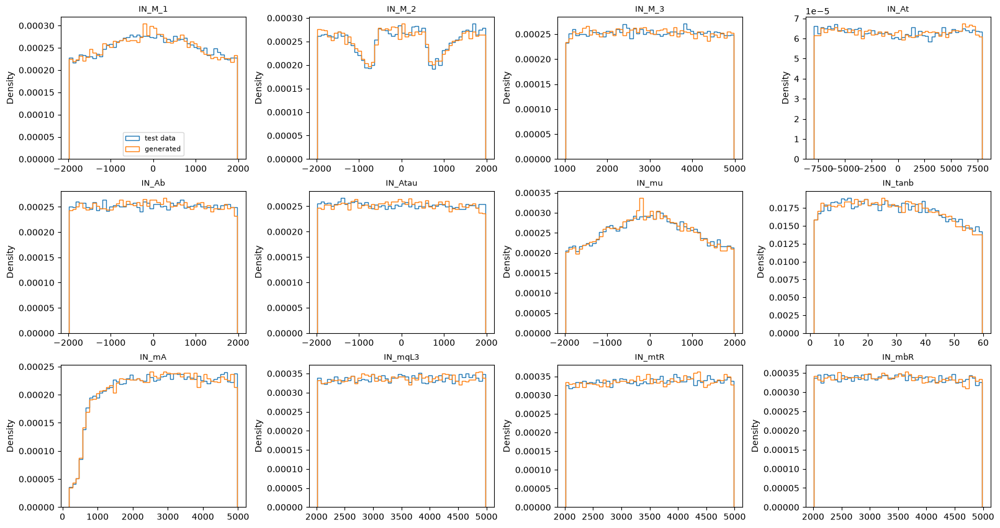

In [17]:
# ---- 3. Inputs from the relic density p(inputs | Omega) ---------------------
gen_inputs = to_physical(results['inputs_given_omega'])
plot_marginals({'test data': truth, 'generated': gen_inputs}, cols=i_inputs)

In [18]:
# plot_gen_vs_truth({'truth': truth, 'generated': gen_inputs}, var_names=names, cols=i_inputs)

/tmp/ipykernel_19929/2977600111.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  band = truth_all[np.abs(np.log10(truth_all[:, i_omega]) - np.log10(omega_0)) < 0.05]


test points with |log10(Omega) - log10(0.12)| < 0.05: 6160


/tmp/ipykernel_19929/1480088054.py:19: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:19: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1791585344983/work/aten/src/ATen/native/IndexingUtils.h:37.)
  rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
/tmp/ipykernel_19929/1480088054.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
/tmp/ipykernel_19929/1480088054.py:22: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered 

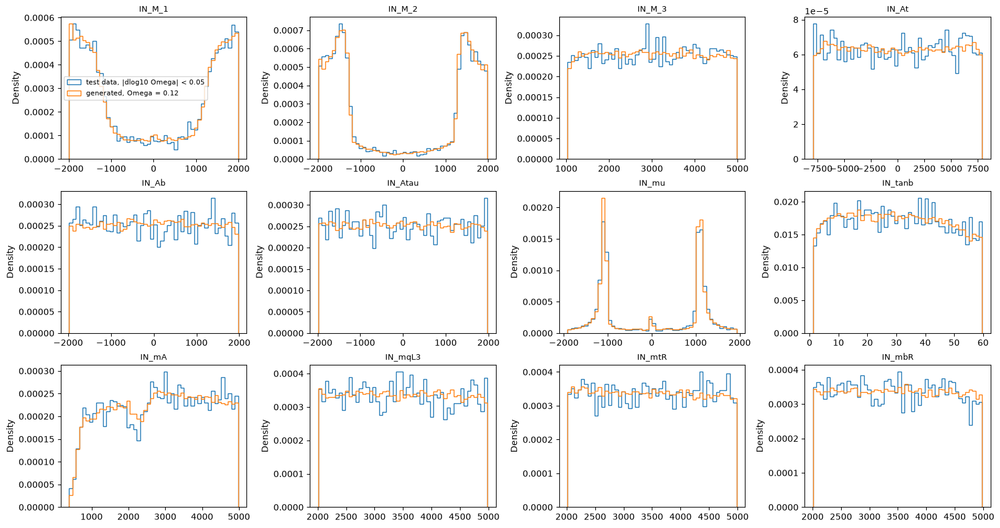

In [19]:
gen_fixed = to_physical(results['inputs_given_omega_fixed'])

band = truth_all[np.abs(np.log10(truth_all[:, i_omega]) - np.log10(omega_0)) < 0.05]
print(f"test points with |log10(Omega) - log10({omega_0})| < 0.05: {len(band)}")
plot_marginals({f'test data, |dlog10 Omega| < 0.05': band, f'generated, Omega = {omega_0}': gen_fixed},
                cols=i_inputs)


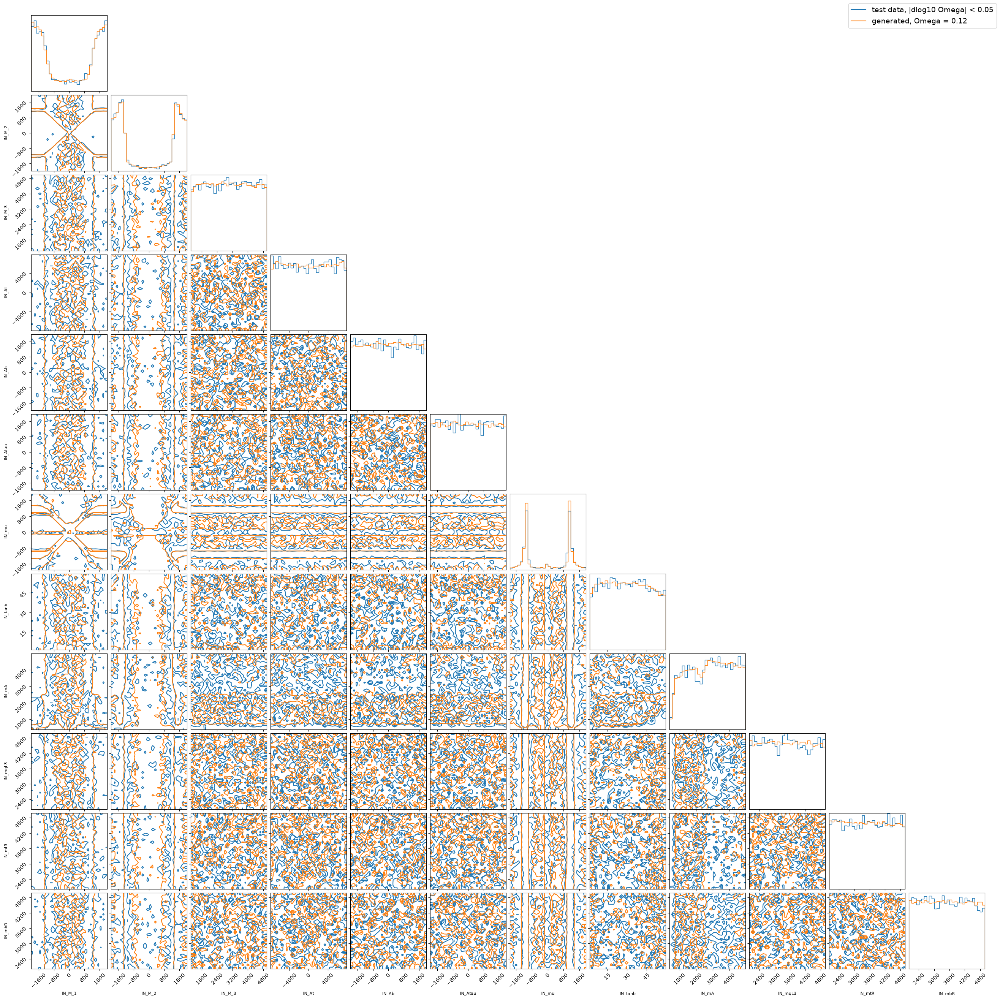

In [20]:
plot_corner({f'test data, |dlog10 Omega| < 0.05': band, f'generated, Omega = {omega_0}': gen_fixed},
                cols=i_inputs)

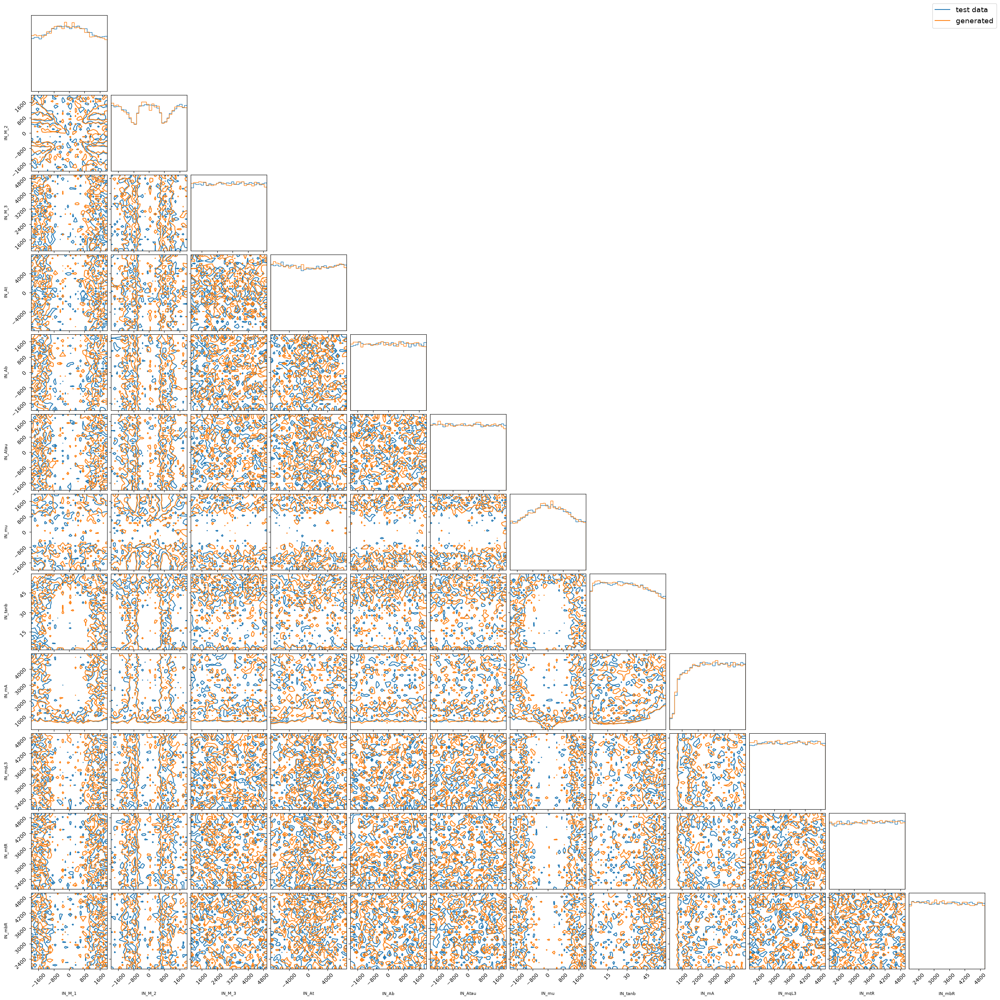

In [ ]:
plot_corner({'test data': truth, 'generated': gen_inputs}, cols=i_inputs)